# Visió Artificial · P1 — Tutorial desde cero

Este notebook recorre **todo lo que necesitas para hacer la P1 (y el examen de prácticas) sin mirar la solución**.

Cómo está organizado:

| Parte | Contenido |
|---|---|
| 0 | Imports y rutas |
| 1 | Qué es una imagen: `shape`, `ndim`, filas/columnas/canales |
| 2 | **Tipos de datos** (`uint8`, `float64`, `bool`) — la fuente nº1 de errores |
| 3 | Crear imágenes con NumPy |
| 4 | Indexación y *slicing* (cómo "pintar" regiones) |
| 5 | Visualizar: `imshow`, `cmap`, **`vmin`/`vmax`**, subplots |
| 6 | Leer y guardar imágenes (`io.imread`, `io.imsave`) |
| 7 | Color: canales RGB, RGBA, `rgb2gray` |
| 8 | **Máscaras booleanas** (umbralizar, seleccionar píxeles, superponer) |
| 9 | Brillo y contraste (*contrast stretching*) |
| 10 | Geometría: voltear, marcos, centrar, `rescale`/`resize` |
| 11 | **La práctica P1 resuelta y explicada**, apartado por apartado |
| 12 | Chuleta de trampas de examen |
| 13 | Ejercicios nuevos tipo examen (con solución plegada) |

> Consejo: ejecuta cada celda y **predice el resultado antes** de verlo. En el examen no tendrás la solución delante; lo que te salva es saber qué `dtype` y qué rango tiene cada imagen en cada momento.

## 0. Imports y rutas

Las tres librerías básicas:

- **NumPy** (`np`): una imagen *es* un array de NumPy. Todo lo que hacemos son operaciones sobre arrays.
- **scikit-image** (`skimage`): leer/guardar (`io`), conversiones de color (`color`), cambios de tipo (`util`), intensidad (`exposure`), tamaño (`transform`).
- **Matplotlib** (`plt`): sólo para **ver** las imágenes. Ver ≠ modificar.

In [1]:
import os
import numpy as np
from matplotlib import pyplot as plt
from skimage import io, data
from skimage.color import rgb2gray, rgba2rgb, gray2rgb
from skimage.util import img_as_ubyte, img_as_float
from skimage.exposure import rescale_intensity
from skimage.transform import rescale, resize

%matplotlib inline

IMG = 'images_notebook/'   # carpeta con las imágenes de la práctica
OUT = 'output'                 # aquí guardaremos lo que generemos
os.makedirs(OUT, exist_ok=True)

## 1. ¿Qué es una imagen?

Una imagen digital es una **matriz de números**. Cada número es un **píxel**.

| Tipo de imagen | `ndim` | `shape` | Ejemplo |
|---|---|---|---|
| Escala de grises / binaria | 2 | `(alto, ancho)` = `(filas, columnas)` | `(800, 1200)` |
| Color RGB | 3 | `(alto, ancho, 3)` | `(800, 1200, 3)` |
| Color RGBA (con transparencia) | 3 | `(alto, ancho, 4)` | `(1188, 915, 4)` |

**Muy importante:** el orden es **(fila, columna)**, es decir **(y, x)**. La fila 0 está **arriba**, la columna 0 a la **izquierda**.

`img[f, c]` → píxel en fila `f`, columna `c`. En una RGB, `img[f, c]` devuelve **3 valores** `[R, G, B]`.

ndim : 2
shape: (3, 4)
size : 12
dtype: int64
min/max: 0 1
píxel (0,1): 0


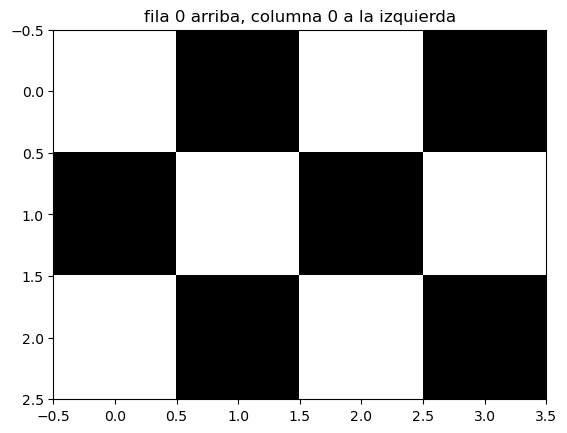

In [2]:
tablero = np.array([[1, 0, 1, 0],
                    [0, 1, 0, 1],
                    [1, 0, 1, 0]])

print('ndim :', tablero.ndim)    # nº de dimensiones
print('shape:', tablero.shape)   # (filas, columnas)
print('size :', tablero.size)    # nº total de elementos = 3*4
print('dtype:', tablero.dtype)   # tipo de cada elemento
print('min/max:', tablero.min(), tablero.max())
print('píxel (0,1):', tablero[0, 1])

plt.imshow(tablero, cmap='gray')
plt.title('fila 0 arriba, columna 0 a la izquierda')
plt.show()

**Propiedades que te pedirán imprimir una y otra vez:** `shape`, `dtype`, `min()`, `max()`. Acostúmbrate a imprimirlas **siempre** después de cada operación: es la mejor herramienta de depuración que tienes.

Agregaciones útiles: `img.mean()`, `img.sum()`, `img.std()`.

⚠️ `img.mean(axis=0)` hace la media **a lo largo de las filas** → te da **una media por columna**. `img.mean(axis=1)` → una media por fila. (El tutorial original lo comenta al revés; compruébalo tú abajo.)

In [3]:
x = np.arange(12).reshape(3, 4)
print(x)
print('mean(axis=0) -> una por columna:', x.mean(axis=0))
print('mean(axis=1) -> una por fila   :', x.mean(axis=1))

[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
mean(axis=0) -> una por columna: [4. 5. 6. 7.]
mean(axis=1) -> una por fila   : [1.5 5.5 9.5]


## 2. Tipos de datos (`dtype`) — LO MÁS IMPORTANTE

| dtype | Rango "de imagen" | Bits | Niveles distintos | Lo produce... |
|---|---|---|---|---|
| `uint8` | 0 … 255 (enteros) | 8 | 2⁸ = **256** | `io.imread` de jpg/png/bmp, `img_as_ubyte` |
| `uint16` | 0 … 65535 | 16 | 2¹⁶ | imágenes médicas, algunos png |
| `float64` | 0.0 … 1.0 (por convenio) | 64 | muchísimos | `rgb2gray`, `img_as_float`, `rescale`, `resize`, dividir `/` |
| `bool` | `False` / `True` | — | 2 | comparaciones (`img > 100`) → imagen **binaria** |

### 2.1 Overflow en `uint8`: los valores dan la vuelta (*wrap-around*)
`uint8` es aritmética **módulo 256**. No hay negativos ni valores > 255:
- `10 - 50 = -40` → se guarda como `-40 + 256 = 216` (¡un oscuro se vuelve claro!)
- `250 + 50 = 300` → se guarda como `300 - 256 = 44`

In [4]:
a = np.array([10, 100, 250], dtype=np.uint8)
print('a     :', a)
print('a - 50:', a - 50, ' <- 10-50 da 216 (wrap-around)')
print('a + 50:', a + 50, ' <- 250+50 da 44')
print('a * 2 :', a * 2,  ' <- 250*2=500 -> 500-256 = 244')
print('dtype resultado:', (a - 50).dtype)

a     : [ 10 100 250]
a - 50: [216  50 200]  <- 10-50 da 216 (wrap-around)
a + 50: [ 60 150  44]  <- 250+50 da 44
a * 2 : [ 20 200 244]  <- 250*2=500 -> 500-256 = 244
dtype resultado: uint8


**Cómo evitarlo:** pasa a `float` (o a un entero más grande como `int16`), opera, **recorta** con `np.clip` y vuelve a `uint8`:

In [5]:
seguro = np.clip(a.astype(float) - 50, 0, 255).astype(np.uint8)
print(seguro)   # [0 50 200]  -> lo que esperábamos

[  0  50 200]


### 2.2 `astype` vs `img_as_*` (pregunta típica)

| Función | ¿Cambia el tipo? | ¿Reescala los valores? |
|---|---|---|
| `img.astype(float)` | Sí | **No**. 255 → 255.0 |
| `img_as_float(img)` | Sí | **Sí**. uint8 [0,255] → float [0,1] (divide entre 255) |
| `img.astype(np.uint8)` | Sí | **No**. Trunca decimales (0.7 → 0) y hace wrap-around si se sale de rango |
| `img_as_ubyte(img)` | Sí | **Sí**. float [0,1] → uint8 [0,255] (multiplica por 255 y redondea). **Da error** si el float está fuera de [-1, 1] |

In [6]:
ii = np.array([[0, 128, 255]], dtype=np.uint8)
print('astype(float):', ii.astype(float))
print('img_as_float :', img_as_float(ii))

f = np.array([0.0, 0.5, 1.0])
print('img_as_ubyte :', img_as_ubyte(f))
print('astype(uint8):', f.astype(np.uint8), '<- ¡todo 0 salvo el 1! (trunca)')

try:
    img_as_ubyte(np.array([0.0, 2.0]))
except ValueError as e:
    print('ERROR img_as_ubyte fuera de rango ->', e)

astype(float): [[  0. 128. 255.]]
img_as_float : [[0.         0.50196078 1.        ]]
img_as_ubyte : [  0 128 255]
astype(uint8): [0 0 1] <- ¡todo 0 salvo el 1! (trunca)
ERROR img_as_ubyte fuera de rango -> Images of type float must be between -1 and 1.


### 2.3 Operaciones "in place" con tipos incompatibles
`arr *= 2.5` sobre un `uint8` **da error** (no puede guardar floats dentro de un array de enteros). `arr * 2.5` sí funciona porque **crea un array nuevo** de tipo float.

Un número decimal escrito en `np.array(..., dtype=np.uint8)` se **trunca**: `25.5 → 25`, `2.55 → 2`.

In [7]:
iarr = np.array([1, 2, 3], dtype=np.uint8)
print((iarr * 2.5), (iarr * 2.5).dtype)   # array nuevo float64
try:
    iarr *= 2.5
except Exception as e:
    print('ERROR:', type(e).__name__)
print(np.array([25.5, 2.55, 255], dtype=np.uint8))

[2.5 5.  7.5] float64
ERROR: UFuncTypeError
[ 25   2 255]


## 3. Crear imágenes con NumPy

| Función | Qué crea |
|---|---|
| `np.zeros((h, w), dtype=np.uint8)` | gris, todo negro |
| `np.zeros((h, w, 3), dtype=np.uint8)` | RGB negra |
| `np.ones(...)`, `255*np.ones(...)` | todo 1 / todo blanco |
| `np.full((h, w), 128, dtype=np.uint8)` | todo a un valor |
| `np.zeros_like(img)`, `np.ones_like(img)` | mismo shape **y dtype** que `img` |
| `np.random.rand(h, w)` | float aleatorio en [0,1) |
| `np.arange(ini, fin, paso)` | vector 1D de valores equiespaciados (fin excluido) |

**Ejercicio del tutorial:** crear un array 100×100×3 de enteros de 32 bits de varias formas:

In [8]:
a1 = np.zeros((100, 100, 3), dtype=np.int32)
a2 = np.ones((100, 100, 3), dtype=np.int32)
a3 = np.full((100, 100, 3), 7, dtype=np.int32)
a4 = np.empty((100, 100, 3), dtype=np.int32)              # sin inicializar (basura)
a5 = np.arange(100*100*3, dtype=np.int32).reshape(100, 100, 3)
a6 = np.random.randint(0, 256, size=(100, 100, 3)).astype(np.int32)
for a in (a1, a2, a3, a4, a5, a6):
    print(a.shape, a.dtype)

(100, 100, 3) int32
(100, 100, 3) int32
(100, 100, 3) int32
(100, 100, 3) int32
(100, 100, 3) int32
(100, 100, 3) int32


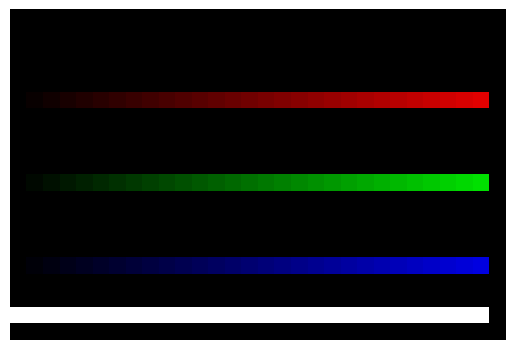

In [9]:
# Imagen RGB negra de 20x30 y "pintamos" degradados en filas sueltas
ii = np.zeros((20, 30, 3), dtype=np.uint8)
ii[5,  0:29, 0] = 8 * np.arange(29)   # fila 5, canal R: degradado 0..224
ii[10, 0:29, 1] = 8 * np.arange(29)   # fila 10, canal G
ii[15, 0:29, 2] = 8 * np.arange(29)   # fila 15, canal B
ii[18, 0:29, :] = [255, 255, 255]     # fila 18, blanco (los 3 canales)
plt.imshow(ii); plt.axis('off'); plt.show()

## 4. Indexación y *slicing*

Esta es **la** herramienta de la práctica: casi todo se resuelve asignando valores a trozos del array.

| Expresión | Significado |
|---|---|
| `img[f, c]` | un píxel |
| `img[a:b, c:d]` | filas `a..b-1`, columnas `c..d-1` (el final **no** se incluye) |
| `img[:, 50:]` | todas las filas, columnas de la 50 al final → **mitad derecha** |
| `img[50:, :]` | filas de la 50 al final → **mitad inferior** |
| `img[:50, :50]` | cuadrante **superior izquierdo** |
| `img[:, :, 0]` | canal R de una imagen color (→ 2D) |
| `img[..., :3]` | los 3 primeros canales (quita alfa en RGBA) |
| `img[::-1, :]` | filas al revés → **volteo vertical** (de arriba a abajo) |
| `img[:, ::-1]` | columnas al revés → **volteo horizontal** (espejo izq-der) |
| `img[-1]` | última fila |

### ⚠️ Vista vs copia
`b = a` **no copia**: `b` y `a` son el mismo array. Un slice `a[0:10]` también es una **vista**: modificarlo modifica `a`. Si quieres trabajar sobre una imagen sin estropear la original: **`b = a.copy()`**.

In [10]:
base = np.zeros((4, 4), dtype=np.uint8)
mala = base           # NO es una copia
mala[0, 0] = 255
print('base tras modificar "mala":\n', base)

base = np.zeros((4, 4), dtype=np.uint8)
buena = base.copy()
buena[0, 0] = 255
print('base tras modificar "buena":\n', base)

base tras modificar "mala":
 [[255   0   0   0]
 [  0   0   0   0]
 [  0   0   0   0]
 [  0   0   0   0]]
base tras modificar "buena":
 [[0 0 0 0]
 [0 0 0 0]
 [0 0 0 0]
 [0 0 0 0]]


## 5. Visualizar: `imshow`, `cmap`, `vmin` / `vmax`, subplots

### 5.1 `cmap`
Un array **2D** no tiene color: `imshow` lo pinta con un *colormap*. Por defecto usa `viridis` (morado-amarillo). Para grises: **`cmap='gray'`**.
Para una imagen **3D (RGB/RGBA)** el `cmap` se **ignora**: los colores salen de los canales.

### 5.2 `vmin` / `vmax` — autocontraste de Matplotlib (¡trampa de examen!)
Por defecto, `imshow` en 2D **estira** el contraste: el valor mínimo de la imagen se pinta negro y el máximo blanco. Así una imagen con valores 80…181 **parece** tener buen contraste aunque no lo tenga.
Para ver los valores **reales**:
- imagen `uint8` → `vmin=0, vmax=255`
- imagen `float` en [0,1] → `vmin=0, vmax=1`

`vmin/vmax` **sólo cambian cómo se ve**, no los datos.

Para RGB: si es `float`, Matplotlib espera [0,1] (recorta lo que se pase → blanco); si es entero, espera [0,255].

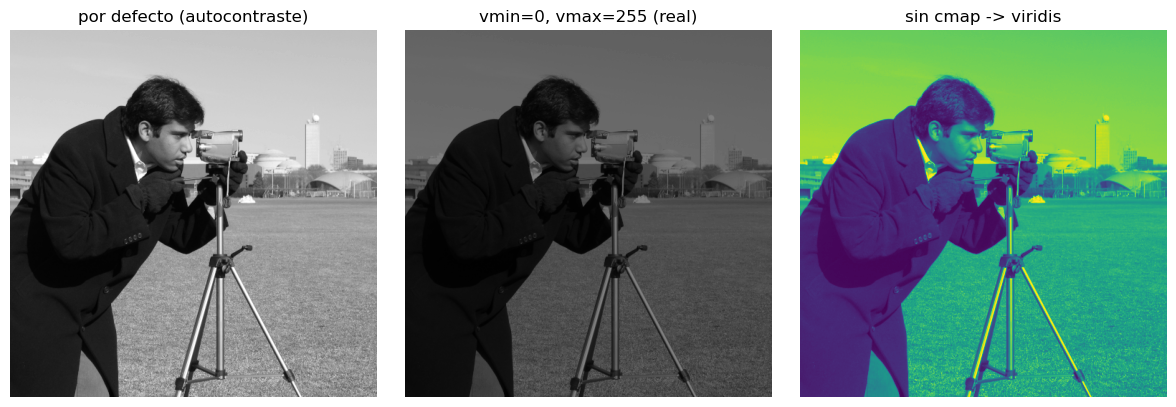

In [11]:
camera = data.camera()            # uint8, 0..255
camera2 = camera / 2              # float64, 0..127.5

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(camera2, cmap='gray');                     axes[0].set_title('por defecto (autocontraste)')
axes[1].imshow(camera2, cmap='gray', vmin=0, vmax=255);   axes[1].set_title('vmin=0, vmax=255 (real)')
axes[2].imshow(camera2);                                  axes[2].set_title('sin cmap -> viridis')
for ax in axes: ax.axis('off')
plt.tight_layout(); plt.show()

### 5.3 Subplots: el patrón que usarás en TODOS los apartados

```python
fig, axes = plt.subplots(1, 3, figsize=(12, 5))   # 1 fila, 3 columnas -> axes es un array de 3
axes[0].imshow(img_a, cmap='gray', vmin=0, vmax=255)
axes[0].set_title('Título A')                     # en un Axes: set_title (no plt.title)
...
for ax in axes:
    ax.axis('off')                                # ocultar ejes
plt.tight_layout()
plt.show()
```

- Con `plt.subplots(2, 2)`, `axes` es 2D → `axes[0, 1]`. Con `axes.ravel()` lo recorres como lista.
- Alternativa antigua: `fig = plt.figure(); fig.add_subplot(1, 3, 1); plt.imshow(...)` (numerado desde **1**).
- "Ocultar ejes" = `ax.axis('off')` (o `plt.axis('off')` si no usas subplots). "Preservar ejes" = no ponerlo.

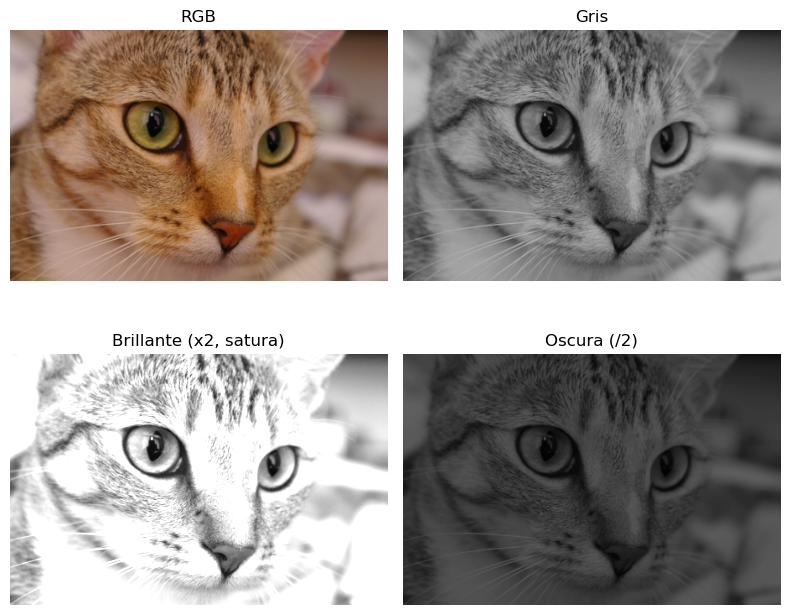

In [12]:
cat = data.chelsea()
gris = rgb2gray(cat)
imgs   = [cat, gris, gris * 2, gris / 2]
titles = ['RGB', 'Gris', 'Brillante (x2, satura)', 'Oscura (/2)']

fig, axes = plt.subplots(2, 2, figsize=(8, 7))
for ax, im, t in zip(axes.ravel(), imgs, titles):
    ax.imshow(im, cmap='gray', vmin=0, vmax=1)   # en el RGB el cmap/vmin se ignoran
    ax.set_title(t); ax.axis('off')
plt.tight_layout(); plt.show()

## 6. Leer y guardar imágenes

```python
img = io.imread('ruta/imagen.jpg')        # -> array NumPy (normalmente uint8)
io.imsave('ruta/salida.png', img)         # guarda un array
```

- Crea la carpeta antes: `os.makedirs('output', exist_ok=True)` (o `if not os.path.exists(...): os.mkdir(...)`).
- Construye rutas con `os.path.join('output', 'rgb_image.png')`.
- **Guarda en `uint8`**. Si tienes un float en [0,1] (p.ej. salida de `rgb2gray`), conviértelo con **`img_as_ubyte`** antes de guardar en JPG.
- **PNG/BMP** son sin pérdida: lo que guardas es lo que lees. **JPG** comprime con pérdida: al releerlo los valores cambian ligeramente.
- Para verificar: relee, imprime `shape`, `dtype` y algún píxel.

In [13]:
prueba = np.zeros((10, 10, 3), dtype=np.uint8)
prueba[:, :5] = [255, 0, 0]
io.imsave(os.path.join(OUT, 'prueba.png'), prueba)
leida = io.imread(os.path.join(OUT, 'prueba.png'))
print(leida.shape, leida.dtype, leida[0, 0], leida[0, 9])

(10, 10, 3) uint8 [255   0   0] [0 0 0]


## 7. Color

### 7.1 Canales
Una RGB `(h, w, 3)` son **tres imágenes en gris apiladas**: `img[:,:,0]` = R, `[:,:,1]` = G, `[:,:,2]` = B.
Al mostrar un canal solo, se ve en **gris**: claro = mucha presencia de ese color. (Un cielo azul se ve claro en el canal B y oscuro en el R.)

Mezclas aditivas a recordar: R+G = **amarillo**, R+B = **magenta**, G+B = **cian**, R+G+B = **blanco**, nada = **negro**.

### 7.2 `rgb2gray`
Convierte `(h, w, 3)` → `(h, w)` y **devuelve float64 en [0,1]** (aunque la entrada sea uint8). Usa una media **ponderada** (el ojo es más sensible al verde):

$$Y = 0.2125\,R + 0.7154\,G + 0.0721\,B$$

(Para RGBA, quita antes el alfa con `rgba2rgb` o `img[..., :3]`.)

In [14]:
puro = np.array([[[255, 0, 0], [0, 255, 0], [0, 0, 255], [255, 255, 255]]], dtype=np.uint8)
print(rgb2gray(puro))          # pesos de R, G, B y blanco = 1
print(rgb2gray(puro).dtype)

g = rgb2gray(puro)
print('gray2rgb ->', gray2rgb(g).shape)   # copia el gris en los 3 canales (se sigue viendo gris)

[[0.2125 0.7154 0.0721 1.    ]]
float64
gray2rgb -> (1, 4, 3)


### 7.3 Intercambiar canales — ¡trampa!
La forma "ingenua" de Python **falla** porque los slices son vistas:

In [15]:
b = np.zeros((1, 1, 3), np.uint8); b[..., 0] = 10; b[..., 2] = 30
b[:, :, 0], b[:, :, 2] = b[:, :, 2], b[:, :, 0]
print('ingenuo  :', b[0, 0], ' <- ¡se pierde el R original!')

b = np.zeros((1, 1, 3), np.uint8); b[..., 0] = 10; b[..., 2] = 30
nueva = b.copy()
nueva[:, :, 0] = b[:, :, 2]     # leemos de la ORIGINAL, escribimos en la copia
nueva[:, :, 2] = b[:, :, 0]
print('con copia:', nueva[0, 0])

print('fancy idx:', b[:, :, [2, 1, 0]][0, 0], ' <- reordenar canales en una línea')

ingenuo  : [30  0 30]  <- ¡se pierde el R original!
con copia: [30  0 10]
fancy idx: [30  0 10]  <- reordenar canales en una línea


### 7.4 RGBA
4º canal = **alfa** (opacidad: 0 transparente, 255 opaco). En la práctica te dicen "modifica sólo RGB (`:3`) y deja el alfa intacto". `rgba2rgb(img)` mezcla con fondo blanco y devuelve float [0,1] con 3 canales.

## 8. Máscaras booleanas

Una **comparación** sobre un array devuelve un array de `bool` del mismo shape: eso es una **máscara** (y también una **imagen binaria**).

```python
mask = img > umbral          # True donde se cumple
img[mask]                    # 1D con los valores donde True
img[mask] = 0                # asigna sólo donde True
img * mask                   # True=1, False=0 -> pone a 0 lo que no cumple
```

Combinar máscaras: `&` (y), `|` (o), `~` (no). **Con paréntesis**: `(img > 50) & (img < 200)`.

### 8.1 Máscaras sobre imágenes de color: `np.any` / `np.all` con `axis=2`
`img[:, :, :3] != 0` tiene shape `(h, w, 3)` (un bool por canal). Para tener **un bool por píxel**:
- `np.any(..., axis=2)` → True si **algún** canal cumple → "píxel no negro"
- `np.all(..., axis=2)` → True si **todos** cumplen → p.ej. "píxel blanco" con `np.all(img == 255, axis=2)`

### 8.2 Indexar con una máscara 2D en una imagen 3D
Si `mask` es `(h, w)` e `img` es `(h, w, 4)`:
- `img[mask]` → shape `(N, 4)`: N píxeles seleccionados, cada uno con sus 4 canales
- `img[mask, :3]` → `(N, 3)`: sólo RGB
- `img[mask, 0]` → `(N,)`: sólo el canal R

Por eso `destino[mask, :3] = origen[mask, :3]` **copia los píxeles seleccionados de una imagen a otra** sin ningún `for`.

coat     : (1188, 915, 4) uint8
mask     : (1188, 915) bool -> píxeles True: 108369
coat[mask]     : (108369, 4)
coat[mask, :3] : (108369, 3)
coat[mask, 0]  : (108369,)


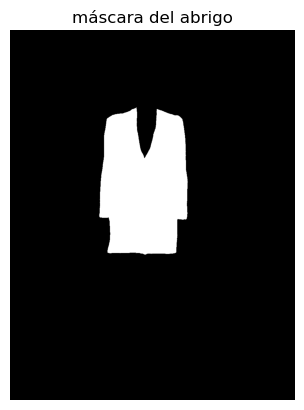

In [16]:
coat = io.imread(IMG + 'coat.png')
mask = np.any(coat[:, :, :3] != 0, axis=2)
print('coat     :', coat.shape, coat.dtype)
print('mask     :', mask.shape, mask.dtype, '-> píxeles True:', mask.sum())
print('coat[mask]     :', coat[mask].shape)
print('coat[mask, :3] :', coat[mask, :3].shape)
print('coat[mask, 0]  :', coat[mask, 0].shape)
plt.imshow(mask, cmap='gray'); plt.title('máscara del abrigo'); plt.axis('off'); plt.show()

In [17]:
# Umbralización con la media (binarizar)
iarr = np.array([[1, 2, 3], [3, 1, 2], [2, 3, 1]], dtype=np.uint8)
mayor = iarr > iarr.mean()
print(mayor)
print(iarr * mayor)         # se queda sólo con los valores > media

[[False False  True]
 [ True False False]
 [False  True False]]
[[0 0 3]
 [3 0 0]
 [0 3 0]]


## 9. Brillo y contraste

Sea una imagen `uint8` con valores entre `Imin` e `Imax` (p.ej. 80…181 → **bajo contraste**: usa sólo 101 de los 256 niveles).

| Operación | Fórmula | Efecto en el rango | ¿Mejora el contraste? |
|---|---|---|---|
| Oscurecer | `I - Imin` | [0, Imax-Imin] | No (sólo desplaza) |
| Aclarar | `I + (255 - Imax)` | [Imin+off, 255] | No (sólo desplaza) |
| **Contrast stretching** | `(I - Imin) / (Imax - Imin)` | **[0, 1]** (float) | **Sí**, usa todo el rango |
| `rescale_intensity(I)` | igual, pero salida en el rango del **dtype** | uint8 → **[0, 255]** | Sí |
| `rescale_intensity(I, out_range=(0, 1))` | | float **[0, 1]** | Sí |

¿Por qué `I - Imin` no hace overflow en uint8? Porque `Imin` es el mínimo: ningún píxel baja de 0. ¿Y `I + (255-Imax)`? Porque el máximo llega justo a 255. Si restaras/sumaras **otro** valor, sí habría wrap-around.

Desplazar = la **diferencia** entre píxeles no cambia → mismo contraste. Estirar = multiplicar → las diferencias crecen → más contraste.

original : (898, 1181) uint8 80 181
dark             uint8 0 101
bright           uint8 154 255
formula          float64 0.0 1.0
rescale_int      uint8 0 255
rescale_int 0-1  float64 0.0 1.0


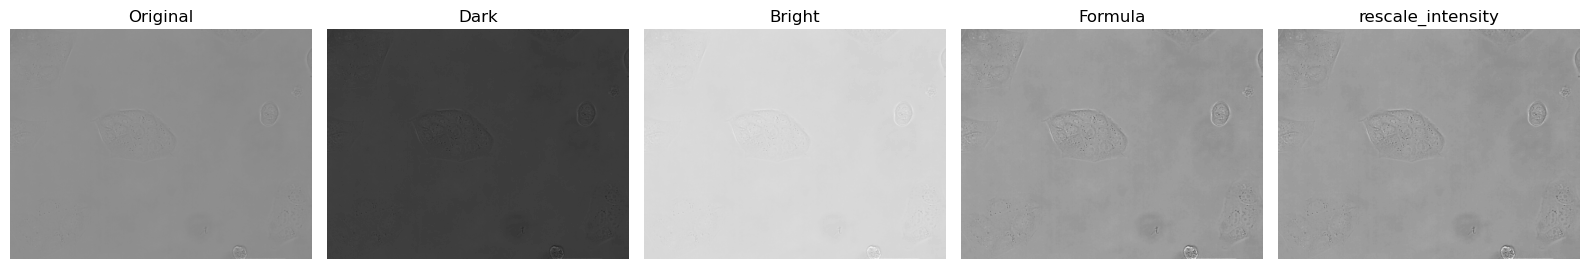

In [18]:
cell = io.imread(IMG + 'cell_lowcontrast2.png')
print('original :', cell.shape, cell.dtype, cell.min(), cell.max())

dark   = cell - cell.min()
bright = cell + (255 - cell.max())
formula = (cell - cell.min()) / (cell.max() - cell.min())   # el '/' ya da float64
ri_u8  = rescale_intensity(cell)
ri_01  = rescale_intensity(cell, out_range=(0, 1))

for n, im in [('dark', dark), ('bright', bright), ('formula', formula),
              ('rescale_int', ri_u8), ('rescale_int 0-1', ri_01)]:
    print(f'{n:16s}', im.dtype, im.min(), im.max())

fig, axes = plt.subplots(1, 5, figsize=(16, 4))
for ax, im, t, vmax in zip(axes, [cell, dark, bright, formula, ri_u8],
                           ['Original', 'Dark', 'Bright', 'Formula', 'rescale_intensity'],
                           [255, 255, 255, 1, 255]):
    ax.imshow(im, cmap='gray', vmin=0, vmax=vmax)   # ¡vmax según el rango de cada imagen!
    ax.set_title(t); ax.axis('off')
plt.tight_layout(); plt.show()

**Pregunta de examen:** ¿por qué sin `vmin/vmax` las 5 imágenes se verían **iguales**? → Porque Matplotlib hace su propio *min-max stretching* al mostrar una imagen 2D, que es exactamente la fórmula de contrast stretching.

Hay también `rescale_intensity(img, in_range=(a, b))`: lo que esté por debajo de `a` → negro, por encima de `b` → blanco, y estira lo de en medio (más contraste aún, a costa de saturar).

## 10. Geometría

### 10.1 Voltear
| Qué | Slicing | NumPy |
|---|---|---|
| Vertical (arriba ↔ abajo) | `img[::-1, :]` | `np.flipud(img)` / `np.flip(img, axis=0)` |
| Horizontal (izq ↔ der) | `img[:, ::-1]` | `np.fliplr(img)` / `np.flip(img, axis=1)` |
| Rotar 90° | | `np.rot90(img)` |
| Transponer (2D) | `img.T` | |

### 10.2 Incrustar una imagen en el centro de otra (marco)
```python
h, w, c = img.shape
H, W = int(h * 1.15), int(w * 1.15)
lienzo = np.zeros((H, W, 3), dtype=np.uint8)
r0 = (H - h) // 2          # // = división entera
c0 = (W - w) // 2
lienzo[r0:r0+h, c0:c0+w] = img          # los shapes deben coincidir EXACTAMENTE
```
Para pintar el marco de un color: asigna a las 4 bandas (`[:r0, :]`, `[r0+h:, :]`, `[:, :c0]`, `[:, c0+w:]`) el valor `[0, 255, 0]`. **Alternativa más corta**: rellenar todo el lienzo de verde y luego pegar la imagen en el centro.

### 10.3 `rescale` y `resize` (`skimage.transform`)
- `rescale(img, 0.5)` → por **factor**. En RGB añade `channel_axis=-1` (si no, también escala los canales).
- `resize(img, (alto, ancho))` → a un **tamaño exacto** (puede deformar si no mantienes la proporción).
- Ambos **devuelven float64 en [0,1]** (interpolan). Para mantener 0..255: `preserve_range=True` (sigue siendo float) o envolver con `img_as_ubyte(...)`.

In [19]:
coins = data.coins()
r1 = rescale(coins, 0.5)
r2 = rescale(coins, 0.5, preserve_range=True)
r3 = img_as_ubyte(resize(coins, (48, 48)))
print('original          ', coins.dtype, coins.shape, coins.min(), coins.max())
print('rescale           ', r1.dtype, r1.shape, round(r1.min(), 3), round(r1.max(), 3))
print('rescale preserve  ', r2.dtype, r2.shape, round(r2.min(), 1), round(r2.max(), 1))
print('img_as_ubyte(resize)', r3.dtype, r3.shape, r3.min(), r3.max())

astro = data.astronaut()
print('RGB rescale con channel_axis:', rescale(astro, 1.15, channel_axis=-1).shape, 'vs', astro.shape)

original           uint8 (303, 384) 1 252
rescale            float64 (152, 192) 0.019 0.916
rescale preserve   float64 (152, 192) 4.8 233.5
img_as_ubyte(resize) uint8 (48, 48) 25 199
RGB rescale con channel_axis: (589, 589, 3) vs (512, 512, 3)


---
# 11. La práctica P1, apartado por apartado

Para cada apartado: **qué piden → idea clave → código**. Intenta escribirlo tú antes de ejecutar la celda.

## 1.1 Creación de imágenes

**a)** Gris 100×100, `uint8`, todo ceros, sin ejes, imprimir dtype.
Idea: `np.zeros` con `dtype`. Muéstrala con `vmin=0, vmax=255` (si no, una imagen constante se ve de un color arbitrario).

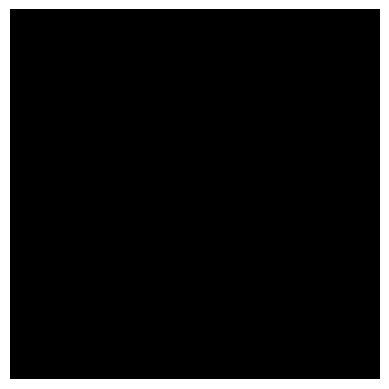

dtype: uint8


In [20]:
img = np.zeros((100, 100), dtype=np.uint8)
plt.imshow(img, cmap='gray', vmin=0, vmax=255); plt.axis('off'); plt.show()
print('dtype:', img.dtype)

**b)** ¿Cuántos niveles puede representar un píxel `uint8`? → **2⁸ = 256** (de 0 a 255): 8 bits, cada uno con 2 estados.

**c)** RGB 100×100×3 `uint8` a ceros → `rgb2gray` → imprimir dtype y shape de ambas.
Idea clave: `rgb2gray` **quita la 3ª dimensión** y **cambia a float64**.

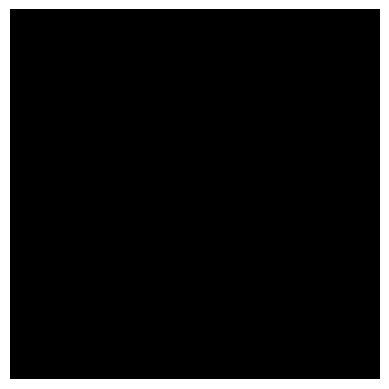

RGB : uint8 (100, 100, 3)
Gray: float64 (100, 100)


In [21]:
img_rgb = np.zeros((100, 100, 3), dtype=np.uint8)
plt.imshow(img_rgb); plt.axis('off'); plt.show()
img_gray = rgb2gray(img_rgb)
print('RGB :', img_rgb.dtype, img_rgb.shape)
print('Gray:', img_gray.dtype, img_gray.shape)

**d)** A partir de la imagen de (a), crear 3 imágenes: mitad derecha blanca, mitad inferior blanca, cuadrante superior izquierdo blanco. 3 subplots e imprimir la primera fila.
Idea: `.copy()` + slicing. Fíjate qué sale al imprimir la 1ª fila: en `img2` todo 0 (la fila 0 está en la mitad de arriba).

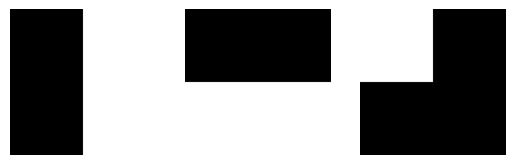

[0 0 0 0 0 0 0 0 0 0] ... [255 255 255 255 255 255 255 255 255 255]
[0 0 0 0 0 0 0 0 0 0] ... [0 0 0 0 0 0 0 0 0 0]
[255 255 255 255 255 255 255 255 255 255] ... [0 0 0 0 0 0 0 0 0 0]


In [22]:
img1 = img.copy(); img1[:, 50:]   = 255   # mitad derecha
img2 = img.copy(); img2[50:, :]   = 255   # mitad inferior
img3 = img.copy(); img3[:50, :50] = 255   # cuadrante sup. izq.

fig, axes = plt.subplots(1, 3)
for ax, im in zip(axes, [img1, img2, img3]):
    ax.imshow(im, cmap='gray', vmin=0, vmax=255); ax.axis('off')
plt.show()
for im in (img1, img2, img3):
    print(im[0, :10], '...', im[0, -10:])

**e)** Voltear verticalmente `img3` ("espejo"), **conservando los ejes** (no pongas `axis('off')`).

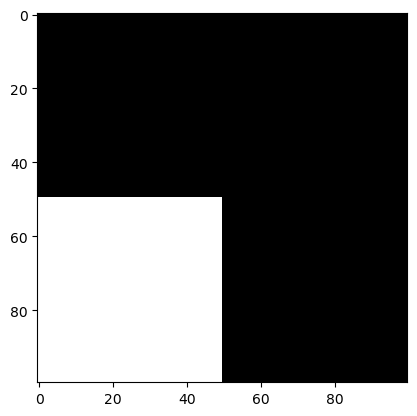

In [23]:
img_flipped = np.flipud(img3)        # == img3[::-1, :] == np.flip(img3, axis=0)
plt.imshow(img_flipped, cmap='gray', vmin=0, vmax=255); plt.show()

**f)** Combinar `img1`, `img2`, `img3` como canales R, G, B.
Razona el resultado por cuadrantes (sup-izq: sólo B → azul; sup-der: sólo R → rojo; inf-izq: G+B → cian; inf-der: R+G → amarillo).

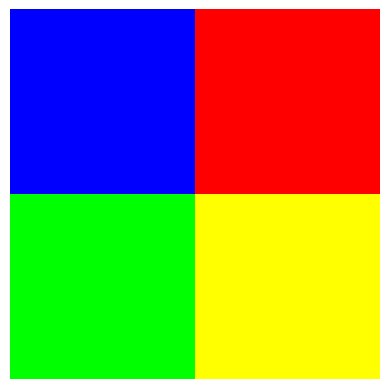

In [24]:
img_color = np.zeros((100, 100, 3), dtype=np.uint8)
img_color[:, :, 0] = img1
img_color[:, :, 1] = img2
img_color[:, :, 2] = img3
# equivalente en una línea: np.stack([img1, img2, img3], axis=2)
plt.imshow(img_color); plt.axis('off'); plt.show()

## 1.2 Guardar y cargar
**a)** Crear carpeta `output` si no existe y guardar `rgb_image.png`. **b)** Releer, mostrar, imprimir shape, píxel `(10,10)` y dtype.
`(10,10)` está en el cuadrante superior izquierdo → sólo B → `[0 0 255]`.

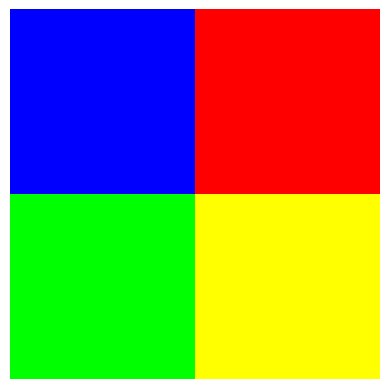

(100, 100, 3) [  0   0 255] uint8


In [25]:
os.makedirs(OUT, exist_ok=True)
io.imsave(os.path.join(OUT, 'rgb_image.png'), img_color)

img_color2 = io.imread(os.path.join(OUT, 'rgb_image.png'))
plt.imshow(img_color2); plt.axis('off'); plt.show()
print(img_color2.shape, img_color2[10, 10], img_color2.dtype)

## 1.3 Manipulaciones básicas

**a)** Cargar `panda.jpg`, imprimir shape/dtype, pasar a gris, mostrarla con `cmap='gray'`, imprimir shape/dtype.

(800, 1200, 3) uint8
(800, 1200) float64


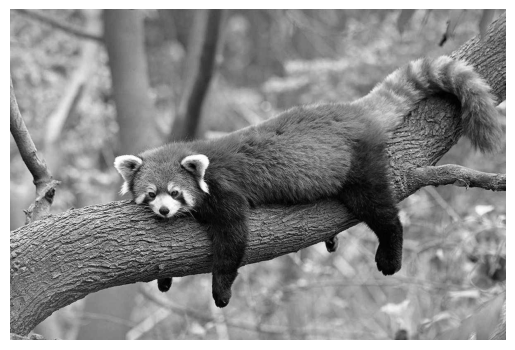

In [26]:
img_panda = io.imread(IMG + 'panda.jpg')
print(img_panda.shape, img_panda.dtype)
img_gray = rgb2gray(img_panda)
print(img_gray.shape, img_gray.dtype)
plt.imshow(img_gray, cmap='gray'); plt.axis('off'); plt.show()

**b)** Guardar la gris como `panda_gray.jpg` → **primero `img_as_ubyte`** (float [0,1] → uint8 [0,255]). Mostrar RGB y gris en 2 subplots e imprimir min/max de: RGB, gris float, gris uint8.

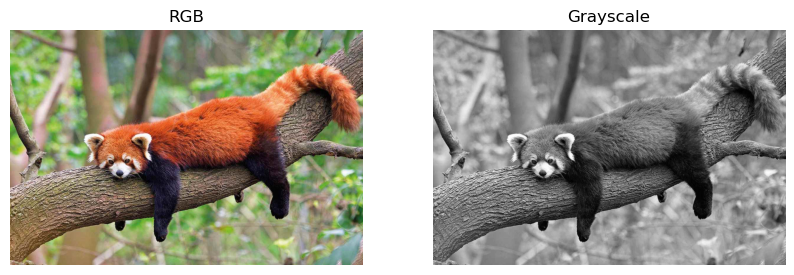

RGB       uint8 0 255
Gray      float64 0.0 1.0
Gray uint8 uint8 0 255


In [27]:
img_gray_u8 = img_as_ubyte(img_gray)
io.imsave(os.path.join(OUT, 'panda_gray.jpg'), img_gray_u8)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(img_panda);              axes[0].set_title('RGB')
axes[1].imshow(img_gray, cmap='gray');  axes[1].set_title('Grayscale')
for ax in axes: ax.axis('off')
plt.show()
print('RGB      ', img_panda.dtype,   img_panda.min(),   img_panda.max())
print('Gray     ', img_gray.dtype,    img_gray.min(),    img_gray.max())
print('Gray uint8', img_gray_u8.dtype, img_gray_u8.min(), img_gray_u8.max())

**c)** Binarizar: píxel > media → 1 (blanco), resto 0. Es una comparación → `bool`. **d)** Original / Grayscale / Binary en 3 subplots con títulos.

bool [False  True]


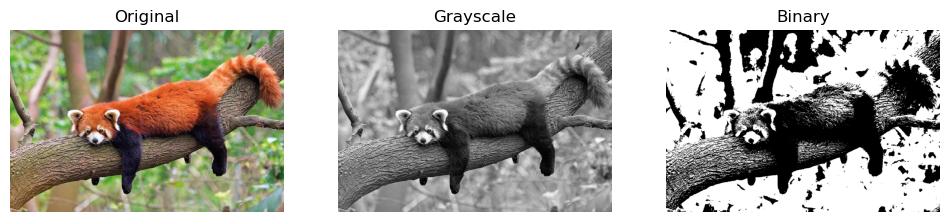

In [28]:
img_binary = img_gray > img_gray.mean()
print(img_binary.dtype, np.unique(img_binary))

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, im, t in zip(axes, [img_panda, img_gray, img_binary], ['Original', 'Grayscale', 'Binary']):
    ax.imshow(im, cmap='gray'); ax.set_title(t); ax.axis('off')
plt.show()

**e)** Lienzo negro 15% más grande, panda centrado. **f)** Marco verde y 3 subplots (Original / Black frame / Green frame).
Ojo: `int(h*1.15)` — los shapes deben ser **enteros**; `//` para el desplazamiento.

(800, 1200, 3) -> (919, 1380, 3)


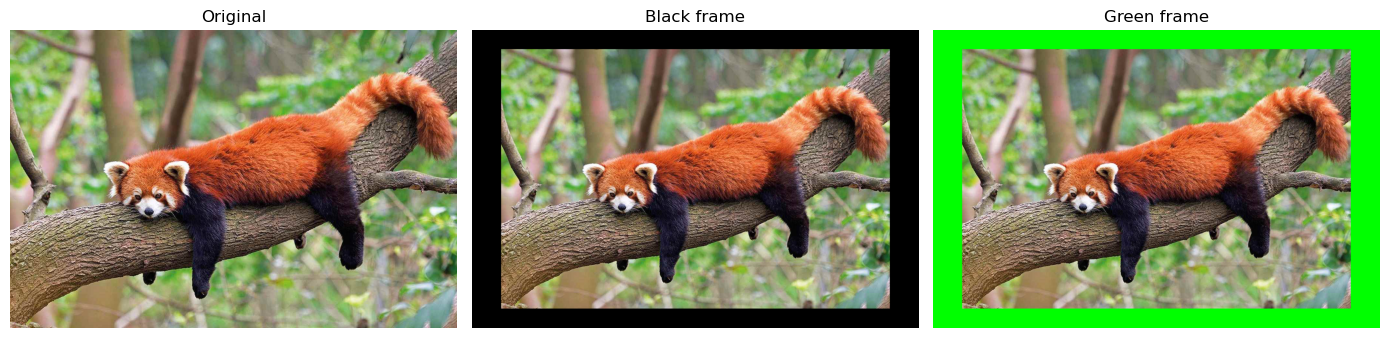

In [29]:
h, w, ch = img_panda.shape
H, W = int(h * 1.15), int(w * 1.15)
r0, c0 = (H - h) // 2, (W - w) // 2

img_black = np.zeros((H, W, 3), dtype=np.uint8)
img_black[r0:r0+h, c0:c0+w] = img_panda
print(img_panda.shape, '->', img_black.shape)

# Marco verde (versión corta: todo verde y pego el panda encima)
img_green = np.zeros((H, W, 3), dtype=np.uint8)
img_green[:] = [0, 255, 0]
img_green[r0:r0+h, c0:c0+w] = img_panda
# Versión de la solución (4 bandas) sobre una copia del negro:
#   g = img_black.copy(); g[:r0] = g[r0+h:] = g[:, :c0] = g[:, c0+w:] = [0, 255, 0]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, im, t in zip(axes, [img_panda, img_black, img_green], ['Original', 'Black frame', 'Green frame']):
    ax.imshow(im); ax.set_title(t); ax.axis('off')
plt.tight_layout(); plt.show()

## 1.4 Brillo y contraste
Ya lo hiciste en la sección 9 con `cell_lowcontrast2.png`. Resumen de lo que piden:

- **a)** mostrar con `vmin=0, vmax=255` e imprimir shape, dtype, min (80), max (181).
- **b)** `dark_image = cell - cell.min()` → rango [0, 101].
- **c)** `bright_im = cell + (255 - cell.max())` → rango [154, 255].
- **d)** los tres juntos, mismos `vmin/vmax`.
- **e)** fórmula `(I - Imin)/(Imax - Imin)` → [0,1] (mostrar con `vmax=1`) y `rescale_intensity` → [0,255] en uint8 (mostrar con `vmax=255`). *El enunciado dice [0,1]; con `rescale_intensity` por defecto sale [0,255] porque respeta el dtype. Si quieres exactamente [0,1]: `out_range=(0, 1)`.*
- **f)** los cinco juntos.

## 1.5 Manipulación de color
**a)** Separar canales de `barcelona.jpg`. **b)** Intercambiar R y B en `chairs.jpg` (recuerda la trampa de 7.3: escribe en una **copia** leyendo de la **original**).

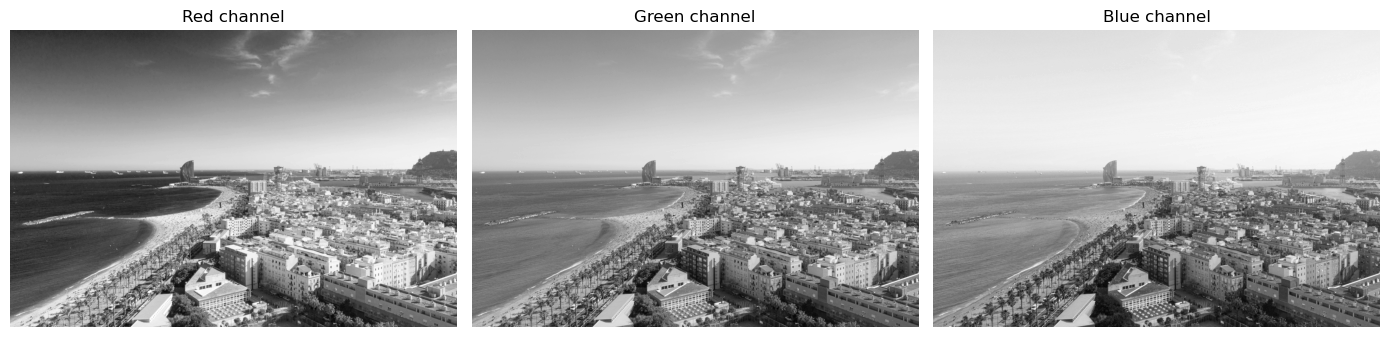

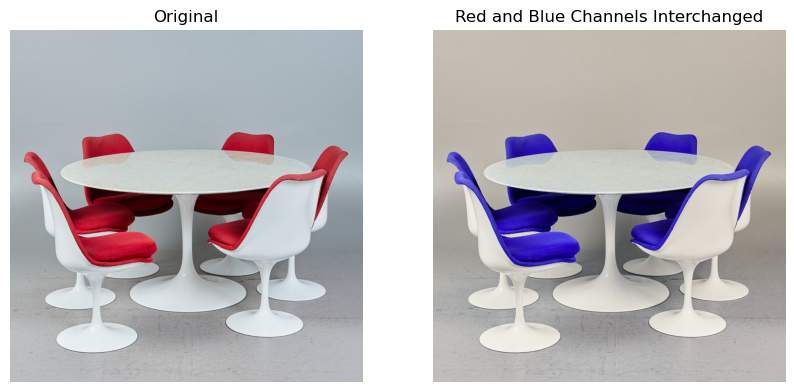

In [30]:
bcn = io.imread(IMG + 'barcelona.jpg')
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for i, (ax, t) in enumerate(zip(axes, ['Red channel', 'Green channel', 'Blue channel'])):
    ax.imshow(bcn[:, :, i], cmap='gray'); ax.set_title(t); ax.axis('off')
plt.tight_layout(); plt.show()

chairs = io.imread(IMG + 'chairs.jpg')
swapped = chairs.copy()
swapped[:, :, 0] = chairs[:, :, 2]
swapped[:, :, 2] = chairs[:, :, 0]          # o: swapped = chairs[:, :, [2, 1, 0]]
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(chairs);  axes[0].set_title('Original')
axes[1].imshow(swapped); axes[1].set_title('Red and Blue Channels Interchanged')
for ax in axes: ax.axis('off')
plt.show()

## 1.6 Máscaras y manipulación lógica

**a)** De `circles.bmp` (fondo **blanco**, 3 círculos), crear 3 imágenes con un solo círculo **en su posición**.
Idea: lienzo **blanco** del mismo shape (`255*np.ones_like(img)` → mantiene uint8) y copiar la franja de columnas.
⚠️ `circles.bmp` tiene shape `(777, 934, 3)`: es RGB aunque se vea en gris. Comprueba siempre shape/dtype/min/max.

(777, 934, 3) uint8 0 255


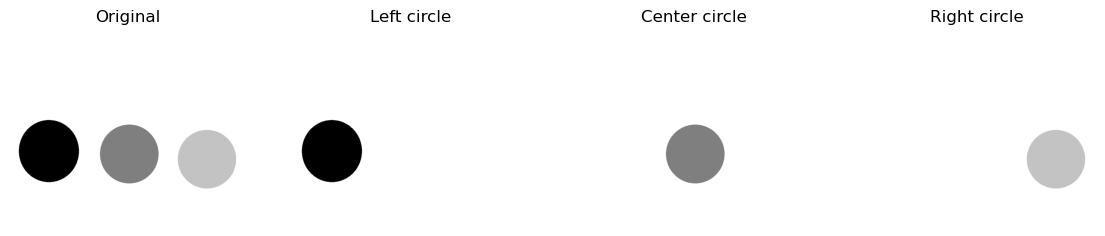

In [31]:
circ = io.imread(IMG + 'circles.bmp')
print(circ.shape, circ.dtype, circ.min(), circ.max())

franjas = [(0, 300), (300, 600), (600, circ.shape[1])]
solos = []
for a, b in franjas:
    nueva = 255 * np.ones_like(circ)
    nueva[:, a:b] = circ[:, a:b]
    solos.append(nueva)

fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, im, t in zip(axes, [circ] + solos, ['Original', 'Left circle', 'Center circle', 'Right circle']):
    ax.imshow(im, cmap='gray', vmin=0, vmax=255); ax.set_title(t); ax.axis('off')
plt.show()

**b)** Tres imágenes con **dos** círculos: copia la original y **borra** (pon a blanco 255) la franja que sobra.

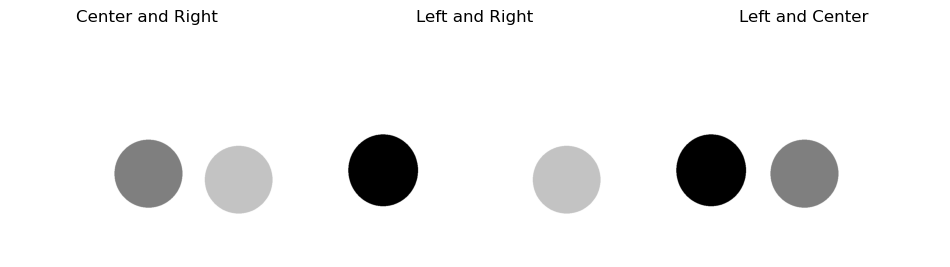

In [32]:
dos = []
for a, b in franjas:
    nueva = circ.copy()
    nueva[:, a:b] = 255
    dos.append(nueva)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, im, t in zip(axes, dos, ['Center and Right', 'Left and Right', 'Left and Center']):
    ax.imshow(im, cmap='gray', vmin=0, vmax=255); ax.set_title(t); ax.axis('off')
plt.show()

**c)** `coat.png` (RGBA): cambiar el color del abrigo intercambiando R y B **sólo en los píxeles no negros**, sin `for`, sin tocar alfa.
Idea: máscara 2D con `np.any(... != 0, axis=2)` sobre `[:, :, :3]` y luego `img[mask, canal]`.

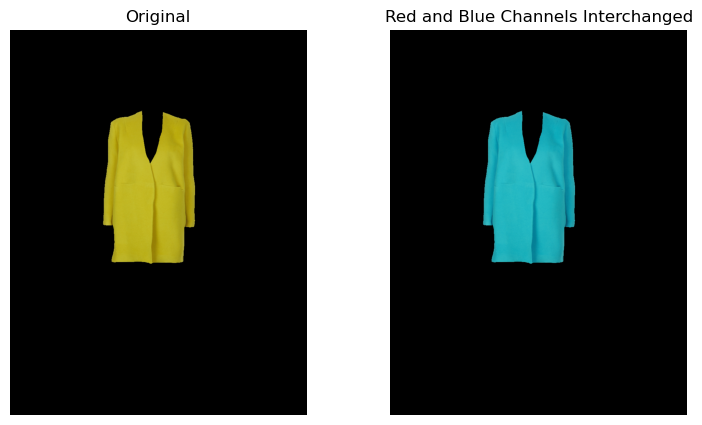

In [33]:
coat = io.imread(IMG + 'coat.png')
mask = np.any(coat[:, :, :3] != 0, axis=2)

coat_changed = coat.copy()
coat_changed[mask, 0] = coat[mask, 2]
coat_changed[mask, 2] = coat[mask, 0]

fig, axes = plt.subplots(1, 2, figsize=(9, 5))
axes[0].imshow(coat);         axes[0].set_title('Original')
axes[1].imshow(coat_changed); axes[1].set_title('Red and Blue Channels Interchanged')
for ax in axes: ax.axis('off')
plt.show()

**d)** Superponer el abrigo (original y cambiado) sobre `model.png`. Ambas son `(1188, 915, 4)` → mismo shape, así que la máscara del abrigo sirve directamente para la modelo.
`modelo[mask, :3] = abrigo[mask, :3]` = "donde hay abrigo, pon los colores del abrigo".

(1188, 915, 4) (1188, 915, 4)


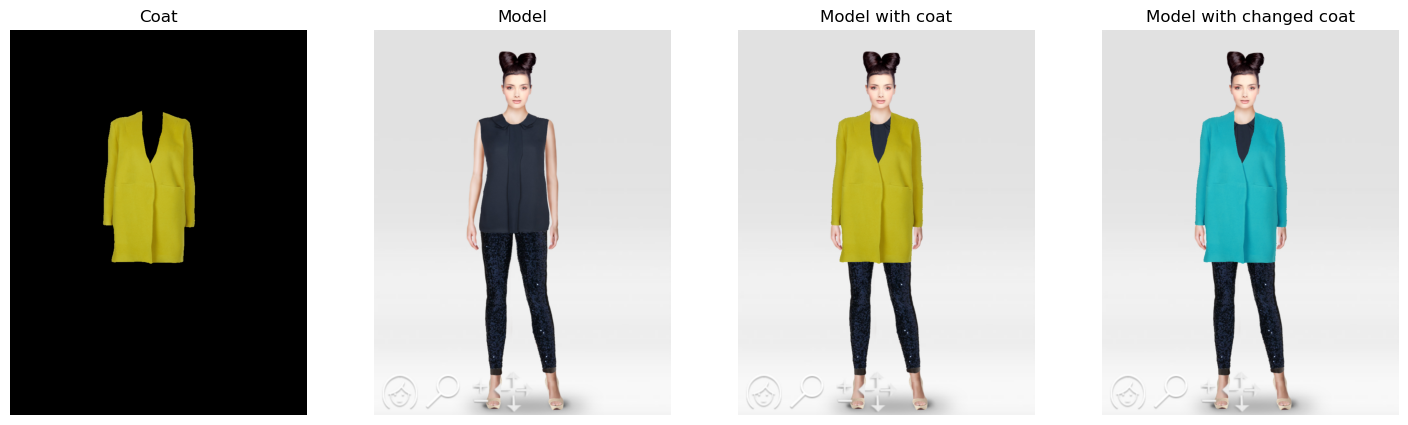

In [34]:
model = io.imread(IMG + 'model.png')
print(model.shape, coat.shape)

model_coat = model.copy()
model_coat[mask, :3] = coat[mask, :3]

model_coat2 = model.copy()
model_coat2[mask, :3] = coat_changed[mask, :3]

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, im, t in zip(axes, [coat, model, model_coat, model_coat2],
                     ['Coat', 'Model', 'Model with coat', 'Model with changed coat']):
    ax.imshow(im); ax.set_title(t); ax.axis('off')
plt.show()

---
# 12. Chuleta de trampas de examen

1. **Imprime siempre `shape`, `dtype`, `min`, `max`** tras cada paso.
2. `uint8` ± algo → **wrap-around** (10−50 = 216). Pasa a `float`/`int16`, opera, `np.clip`, vuelve.
3. `rgb2gray`, `img_as_float`, `rescale`, `resize`, `/` → devuelven **float64**. `rgb2gray` además en **[0,1]**.
4. Para guardar un float [0,1] → **`img_as_ubyte`**, no `astype(np.uint8)` (que trunca todo a 0).
5. `imshow` en 2D **autoescala** el contraste → usa `vmin/vmax` (0–255 para uint8, 0–1 para float).
6. Imagen 2D sin `cmap='gray'` → sale en **viridis** (morado/amarillo).
7. `b = a` no copia. Usa **`.copy()`** antes de modificar.
8. Intercambiar canales: escribe en la copia, **lee de la original**. O `img[:, :, [2, 1, 0]]`.
9. `img[f, c]` = (fila, columna) = (**y**, x). La fila 0 está arriba.
10. Slicing: el final **no** se incluye (`[0:50]` = 0…49).
11. Tamaños calculados (15% más) → `int(...)`; desplazamientos → `//`.
12. RGBA: opera en `[..., :3]` y deja `[..., 3]` (alfa) intacto.
13. Máscara por píxel en color → `np.any(..., axis=2)` / `np.all(..., axis=2)`.
14. Combinar condiciones: `&`, `|`, `~` **con paréntesis**.
15. Sin bucles `for` por píxel: usa slicing y máscaras.
16. `rescale` en RGB → `channel_axis=-1`.
17. Volteo vertical = `flipud` = `[::-1, :]`; horizontal = `fliplr` = `[:, ::-1]`.
18. Subplots: `axes[i].set_title(...)`, `ax.axis('off')`, `plt.tight_layout()`, `plt.show()`.

---
# 13. Ejercicios tipo examen

Hazlos **sin mirar** la solución (está plegada en "▶ Solución"). Todos usan sólo lo visto arriba.

**E1.** Crea una imagen gris `uint8` de 200×200 negra con una **cruz blanca** centrada de 20 píxeles de grosor (una franja horizontal y una vertical). Muéstrala sin ejes y con el rango real.

In [35]:
# Tu solución

<details><summary>▶ Solución</summary>

```python
img = np.zeros((200, 200), dtype=np.uint8)
img[90:110, :] = 255
img[:, 90:110] = 255
plt.imshow(img, cmap='gray', vmin=0, vmax=255); plt.axis('off'); plt.show()
```
</details>

**E2.** Crea un **degradado horizontal** 100×256 `uint8` (columna `j` vale `j`). Pista: `np.arange` + *broadcasting* o `np.tile`. Muéstralo con y sin `vmin/vmax` y explica por qué se ven igual.

In [36]:
# Tu solución

<details><summary>▶ Solución</summary>

```python
grad = np.tile(np.arange(256, dtype=np.uint8), (100, 1))
# o: grad = np.zeros((100, 256), np.uint8); grad[:] = np.arange(256)
print(grad.shape, grad.min(), grad.max())
# Se ven igual porque min=0 y max=255: el autoescalado de imshow coincide con el rango real.
```
</details>

**E3.** Carga `panda.jpg` y crea su **negativo** (`255 - img`). Muestra original y negativo. ¿Hay riesgo de overflow? ¿Por qué?

In [37]:
# Tu solución

<details><summary>▶ Solución</summary>

```python
p = io.imread(IMG + 'panda.jpg')
neg = 255 - p
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(p); axes[1].imshow(neg)
for ax in axes: ax.axis('off')
plt.show()
# No hay overflow: p está en [0,255] => 255-p también está en [0,255].
```
</details>

**E4.** Con `barcelona.jpg`, crea tres imágenes RGB donde sólo se conserve **un** canal (los otros a 0) y muéstralas en color (no en gris).

In [38]:
# Tu solución

<details><summary>▶ Solución</summary>

```python
bcn = io.imread(IMG + 'barcelona.jpg')
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for i, t in enumerate(['Solo R', 'Solo G', 'Solo B']):
    solo = np.zeros_like(bcn)
    solo[:, :, i] = bcn[:, :, i]
    axes[i].imshow(solo); axes[i].set_title(t); axes[i].axis('off')
plt.show()
```
</details>

**E5.** Calcula a mano la gris de `chairs.jpg` con los pesos de `rgb2gray` y comprueba con `np.allclose` que coincide con `rgb2gray` (pista: pasa a `img_as_float` primero).

In [39]:
# Tu solución

<details><summary>▶ Solución</summary>

```python
ch = img_as_float(io.imread(IMG + 'chairs.jpg'))
mano = 0.2125 * ch[:, :, 0] + 0.7154 * ch[:, :, 1] + 0.0721 * ch[:, :, 2]
print(np.allclose(mano, rgb2gray(ch)))
```
</details>

**E6.** En `panda.jpg` (gris), pinta en **rojo** sobre la imagen RGB original todos los píxeles cuya gris sea **menor que 0.2** (zonas muy oscuras). Sin `for`.

In [40]:
# Tu solución

<details><summary>▶ Solución</summary>

```python
p = io.imread(IMG + 'panda.jpg')
oscuro = rgb2gray(p) < 0.2          # máscara 2D
res = p.copy()
res[oscuro] = [255, 0, 0]           # img[mask] es (N,3): le asignamos un color
plt.imshow(res); plt.axis('off'); plt.show()
```
</details>

**E7.** A `cell_lowcontrast2.png` súmale 100 de dos maneras: (a) directamente en `uint8`, (b) sin overflow (saturando a 255). Muestra ambas con `vmin=0, vmax=255` e imprime min/max. Explica la diferencia.

In [41]:
# Tu solución

<details><summary>▶ Solución</summary>

```python
cell = io.imread(IMG + 'cell_lowcontrast2.png')
a = cell + 100                                               # 181+100=281 -> 25 (wrap)
b = np.clip(cell.astype(np.int16) + 100, 0, 255).astype(np.uint8)
print('a', a.min(), a.max(), '| b', b.min(), b.max())
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(a, cmap='gray', vmin=0, vmax=255); axes[0].set_title('uint8 directo (wrap)')
axes[1].imshow(b, cmap='gray', vmin=0, vmax=255); axes[1].set_title('saturado')
for ax in axes: ax.axis('off')
plt.show()
```
</details>

**E8.** Haz un *contrast stretching* de `cell_lowcontrast2.png` al rango **[50, 200]** en `uint8` con la fórmula (y compruébalo con `rescale_intensity(..., out_range=(50, 200))`).

In [42]:
# Tu solución

<details><summary>▶ Solución</summary>

```python
cell = io.imread(IMG + 'cell_lowcontrast2.png').astype(float)
s = (cell - cell.min()) / (cell.max() - cell.min())   # [0,1]
s = (50 + s * (200 - 50)).round().astype(np.uint8)    # [50,200]
r = rescale_intensity(cell, out_range=(50, 200)).round().astype(np.uint8)
print(s.min(), s.max(), np.array_equal(s, r))
```
</details>

**E9.** Crea un mosaico 2×2 con el panda: arriba-izq original, arriba-der volteado horizontalmente, abajo-izq volteado verticalmente, abajo-der rotado 180°. Todo en **una sola imagen** (no subplots). Pista: `np.concatenate` o un lienzo de `(2h, 2w, 3)`.

In [43]:
# Tu solución

<details><summary>▶ Solución</summary>

```python
p = io.imread(IMG + 'panda.jpg')
h, w, _ = p.shape
mos = np.zeros((2*h, 2*w, 3), dtype=np.uint8)
mos[:h, :w] = p
mos[:h, w:] = p[:, ::-1]
mos[h:, :w] = p[::-1, :]
mos[h:, w:] = p[::-1, ::-1]
plt.imshow(mos); plt.axis('off'); plt.show()
```
</details>

**E10.** En `circles.bmp`, cuenta cuántos píxeles son **negros** (los tres canales a 0) y qué porcentaje de la imagen representan. Luego pinta los círculos en **azul** dejando el fondo blanco.

In [44]:
# Tu solución

<details><summary>▶ Solución</summary>

```python
c = io.imread(IMG + 'circles.bmp')
negros = np.all(c == 0, axis=2)
print(negros.sum(), 'píxeles,', 100 * negros.mean(), '%')
azul = c.copy()
azul[~(np.all(c == 255, axis=2))] = [0, 0, 255]   # todo lo que no es blanco -> azul
plt.imshow(azul); plt.axis('off'); plt.show()
```
</details>

**E11.** Pon el abrigo sobre la modelo pero **verde**: crea `coat_green` donde los píxeles del abrigo tengan su canal G = el antiguo R, y R = el antiguo G (B igual). Muéstralo sobre la modelo.

In [45]:
# Tu solución

<details><summary>▶ Solución</summary>

```python
coat = io.imread(IMG + 'coat.png'); model = io.imread(IMG + 'model.png')
mask = np.any(coat[:, :, :3] != 0, axis=2)
cg = coat.copy()
cg[mask, 0] = coat[mask, 1]
cg[mask, 1] = coat[mask, 0]
out = model.copy()
out[mask, :3] = cg[mask, :3]
plt.imshow(out); plt.axis('off'); plt.show()
```
</details>

**E12. (preguntas teóricas rápidas)**
1. Shape y dtype de `rgb2gray(io.imread('x.jpg'))`?
2. ¿Qué valor queda en `np.uint8(200) + np.uint8(100)`?
3. ¿Qué diferencia hay entre `rescale` y `resize`?
4. ¿Por qué `img_as_ubyte(np.array([0., 2.]))` da error?
5. ¿Qué devuelve `img[mask]` si `img` es `(h,w,3)` y `mask` es `(h,w)` con N `True`?

In [46]:
# Tu solución

<details><summary>▶ Solución</summary>

```python
# 1. (h, w), float64 en [0,1]
# 2. 44  (300 - 256)
# 3. rescale: por factor de escala; resize: a un shape concreto (puede deformar)
# 4. img_as_ubyte espera floats en [-1, 1]; 2.0 está fuera de rango
# 5. un array (N, 3): los N píxeles seleccionados con sus 3 canales
```
</details>